# Random-forest default forecaster: step by step

This notebook rebuilds the model behind **`5_default_forecaster.html`** one step at a time, so every choice can be checked and changed.

It does the same job as `build_model.py`, in the same order, and its last section can write `data/model.js` for the dashboard.
`build_model.py` is still the one-command way to rebuild. **If you change something here, make the same change in the script** (or just export from here, see section 9).

| Section | What happens |
|---|---|
| 1 | Settings and data paths |
| 2 | Load the raw CSVs |
| 3 | The leakage rule: only use history from before each loan |
| 4 | Build the 17 features |
| 5 | The model |
| 6 | Cross-validation: held-out scores, cut-off, accuracy, importance |
| 7 | Why the cash-share grid is uneven |
| 8 | What-if curves (cash share moved, everything else fixed) |
| 9 | Check against the current `model.js` and optionally export |

Needs: `pandas`, `numpy`, `scikit-learn`, `matplotlib`. Run it from the `Dashboards/prep` folder.

## 1 · Settings
All the knobs are here. Change them, then *Run All*.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold

PREP = Path.cwd()                       # .../Dashboards/prep
ROOT = PREP.parent                      # .../Dashboards
DATA = ROOT.parents[1] / "Tangerine"    # raw CSVs: same default as build_model.py
assert (DATA / "loans.csv").exists(), f"CSVs not found in {DATA}: set DATA by hand"

SEED = 42
N_TREES, MAX_DEPTH, MIN_LEAF = 300, 6, 5   # forest size and how deep/fine each tree may grow
FOLDS = 5                                  # cross-validation folds
WRITE_MODEL_JS = False                     # set True to overwrite data/model.js in section 9

pd.set_option("display.width", 160, "display.max_columns", 30)
print("data:", DATA)

data: d:\Sheridan Hackathon\Tangerine


## 2 · Load the raw tables
One row per loan is the unit we predict. `defaulted` is the target (1 = defaulted).

In [2]:
loans   = pd.read_csv(DATA / "loans.csv")
acc     = pd.read_csv(DATA / "accounts.csv")
disp    = pd.read_csv(DATA / "dispositions.csv")
cards   = pd.read_csv(DATA / "cards.csv")
clients = pd.read_csv(DATA / "clients.csv")
dist    = pd.read_csv(DATA / "districts.csv")
ms      = pd.read_csv(DATA / "monthly_summary.csv")   # one row per account per month

for name, df in [("loans", loans), ("accounts", acc), ("dispositions", disp), ("cards", cards),
                 ("clients", clients), ("districts", dist), ("monthly_summary", ms)]:
    print(f"{name:16s} {df.shape}")
print(f"\n{len(loans)} loans, {loans.defaulted.sum()} defaulted ({loans.defaulted.mean():.1%})")
print("one loan per account:", loans.account_id.is_unique)
loans.head()

loans            (682, 9)
accounts         (4500, 4)
dispositions     (5369, 4)
cards            (892, 4)
clients          (5369, 4)
districts        (77, 16)
monthly_summary  (185326, 19)

682 loans, 76 defaulted (11.1%)
one loan per account: True


,loan_id,account_id,loan_start,amount,duration_months,monthly_payment,status,status_meaning,defaulted
0,103082,55447,2025-04-02,175611.84,48,3658.58,C,"running, OK so far",0
1,106778,22715,2025-07-29,132615.00,36,3683.75,C,"running, OK so far",0
2,107687,72211,2023-01-19,56558.88,24,2356.62,A,"finished, repaid",0
3,108424,57243,2025-04-23,213428.16,48,4446.42,C,"running, OK so far",0
4,109366,66505,2022-05-24,118969.80,60,1982.83,C,"running, OK so far",0


## 3 · The leakage rule

A loan's outcome changes the account *after* the loan starts: a borrower who is defaulting goes overdrawn and gets penalty interest.
If the model saw those months it would be "predicting" the default from its own symptoms, and the accuracy would look far better than anything usable at approval time.

**Rule: every account feature uses only `monthly_summary` months strictly before the loan's start month.**

The cell below shows why this matters. It compares one feature, days below zero, measured before and after the loan started.

In [3]:
loans["start_month"] = loans.loan_start.str[:7]           # 'YYYY-MM', same format as ms.month
m = ms.merge(loans[["account_id", "start_month", "defaulted"]], on="account_id")
pre_m, post_m = m[m.month < m.start_month], m[m.month >= m.start_month]

neg = pd.DataFrame({"pre":  pre_m.groupby("account_id").days_below_zero.sum(),
                    "post": post_m.groupby("account_id").days_below_zero.sum()}).fillna(0)
neg = neg.join(loans.set_index("account_id").defaulted)
for col in ["pre", "post"]:
    print(f"days below zero {col:4s} the loan: AUC on its own = {roc_auc_score(neg.defaulted, neg[col]):.3f}")
print("\nThe post-loan version is the leak: it mostly measures the default itself. We only use 'pre'.")

days below zero pre  the loan: AUC on its own = 0.678
days below zero post the loan: AUC on its own = 0.921

The post-loan version is the leak: it mostly measures the default itself. We only use 'pre'.


In [4]:
months_pre = pre_m.groupby("account_id").size()
print("loans with NO pre-loan history:", len(set(loans.account_id) - set(months_pre.index)))
print("pre-loan months per loan:", months_pre.describe()[["min", "50%", "max"]].to_dict())

loans with NO pre-loan history: 0
pre-loan months per loan: {'min': 3.0, '50%': 13.0, 'max': 23.0}


## 4 · Build the features (17 per loan)

### 4a · Account behaviour, pre-loan months only
- **cash_share**: cash deposits ÷ all money in, over all pre-loan months. *This is the slider variable on the dashboard.*
- **income / spending**: median monthly money in / out
- **balance**: mean average-daily-balance over the last 6 pre-loan months
- **neg_days**: total days the balance was below zero

In [5]:
pre = pre_m.sort_values(["account_id", "month"])
assert (pre.month < pre.start_month).all()                 # leakage guard
g = pre.groupby("account_id")
beh = pd.DataFrame({
    "months_pre": g.size(),
    "cash_share": g.cash_deposits.sum() / (g.money_in.sum() + 1e-6),
    "income":     g.money_in.median(),
    "spending":   g.money_out.median(),
    "balance":    g.tail(6).groupby("account_id").avg_daily_balance.mean(),
    "neg_days":   g.days_below_zero.sum(),
})
beh.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
months_pre,682.0,13.076,5.415,3.000,9.000,13.000,17.000,23.00
cash_share,682.0,0.694,0.449,0.000,0.041,0.991,0.994,1.00
income,682.0,15448.726,9400.222,94.390,8557.848,13539.045,21975.988,43198.76
spending,682.0,13049.449,8251.441,0.000,6980.149,11244.110,18587.348,49901.11
balance,682.0,25638.693,9216.552,273.108,18555.075,25091.755,32200.168,53178.86
neg_days,682.0,0.661,5.100,0.000,0.000,0.000,0.000,78.00


### 4b · Loan terms
`pti` = monthly payment ÷ median monthly income (income clipped at 1 to avoid dividing by zero).

In [6]:
X = (loans[["loan_id", "account_id", "loan_start", "defaulted", "amount", "duration_months", "monthly_payment"]]
     .rename(columns={"duration_months": "duration", "monthly_payment": "payment"})
     .merge(beh, left_on="account_id", right_index=True))
X["pti"] = X.payment / X.income.clip(lower=1)
X[["amount", "duration", "payment", "pti"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
amount,682.0,95277.885,71341.856,3133.800,41992.440,73579.260,132558.330,371785.200
duration,682.0,36.493,17.075,12.000,24.000,36.000,48.000,60.000
payment,682.0,2637.059,1394.356,191.300,1558.700,2475.550,3658.265,6236.070
pti,682.0,0.702,2.948,0.015,0.107,0.165,0.245,32.647


### 4c · Household
- **joint**: the account has an "authorized user" besides the owner
- **card**: a card was issued **before** the loan started (later cards are left out, same leakage rule)

In [7]:
X["joint"] = X.account_id.isin(disp.loc[disp.type == "authorized user", "account_id"]).astype(int)

cd = (disp.merge(cards, on="disposition_id")[["account_id", "issued"]]
          .merge(loans[["account_id", "loan_start"]], on="account_id"))
X["card"] = X.account_id.isin(cd.loc[cd.issued < cd.loan_start, "account_id"]).astype(int)
print("cards on loan accounts:", len(cd), "| issued before the loan:", (cd.issued < cd.loan_start).sum(),
      "| after (ignored):", (cd.issued >= cd.loan_start).sum())
X.groupby("joint").defaulted.agg(["size", "mean"]).rename(columns={"mean": "default_rate"})

cards on loan accounts: 170 | issued before the loan: 36 | after (ignored): 134


,size,default_rate
joint,,
0,537,0.141527
1,145,0.000000


### 4d · Statement frequency (one-hot: monthly / weekly / after each transaction)

In [8]:
freq = acc.set_index("account_id").frequency.map({
    "monthly statement": "monthly", "weekly statement": "weekly",
    "statement after each transaction": "per_tx"})
for f in ["monthly", "weekly", "per_tx"]:
    X[f"freq_{f}"] = (X.account_id.map(freq) == f).astype(int)
X[["freq_monthly", "freq_weekly", "freq_per_tx"]].sum()

freq_monthly    559
freq_weekly      91
freq_per_tx      32
dtype: int64

### 4e · District and owner
District average salary and unemployment rate, and the owner's age on the loan start date.

In [9]:
d = acc.set_index("account_id").district_id.map(
    dist.set_index("district_id")[["average_salary", "unemployment_rate_2023"]].to_dict("index"))
X["district_salary"] = X.account_id.map(lambda a: d[a]["average_salary"])
X["district_unemp"]  = X.account_id.map(lambda a: d[a]["unemployment_rate_2023"])
owner = disp[disp.type == "owner"].merge(clients, on="client_id").set_index("account_id").birth_date
X["age"] = (pd.to_datetime(X.loan_start) - pd.to_datetime(X.account_id.map(owner))).dt.days / 365.25
X = X.reset_index(drop=True)
X[["district_salary", "district_unemp", "age"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
district_salary,682.0,5979.95,832.62,5103.38,5376.48,5657.77,6227.89,7891.68
district_unemp,682.0,3.53,2.15,0.43,1.96,3.49,4.79,9.40
age,682.0,38.15,12.78,13.57,27.27,37.65,48.92,61.84


### 4f · The final feature table
The keys are the model's columns; the values are the labels the dashboard shows. Drop a key here to remove a feature from the model.

In [10]:
FEATURES = {
    "cash_share": "Cash share of income",
    "income": "Median monthly income",
    "spending": "Median monthly spending",
    "balance": "Average balance (last 6 months)",
    "neg_days": "Days below zero",
    "amount": "Loan amount",
    "duration": "Loan length (months)",
    "payment": "Monthly payment",
    "pti": "Payment-to-income ratio",
    "joint": "Joint account",
    "card": "Has a card",
    "freq_monthly": "Monthly statements",
    "freq_weekly": "Weekly statements",
    "freq_per_tx": "Statement after each transaction",
    "district_salary": "District average salary",
    "district_unemp": "District unemployment rate",
    "age": "Owner's age at loan start",
}
cols = list(FEATURES)
y = X.defaulted
assert len(X) == len(loans) and X[cols].notna().all().all(), "missing rows or values"
print(f"{len(X)} rows x {len(cols)} features, {y.sum()} defaults")
# mean of each feature for repaid (0) vs defaulted (1): a quick sanity check before modelling
X.groupby("defaulted")[cols].mean().T.round(3)

682 rows x 17 features, 76 defaults


defaulted,0,1
cash_share,0.676,0.832
income,15637.219,13945.746
spending,13187.349,11949.875
balance,26460.925,19082.481
neg_days,0.000,5.934
amount,91048.510,129001.590
duration,36.337,37.737
payment,2547.038,3354.862
pti,0.547,1.939
joint,0.239,0.000


## 5 · The model

A random forest of `N_TREES` trees.
- `max_depth` and `min_samples_leaf` keep each tree small, so it can't memorise 682 rows.
- `class_weight="balanced"` makes each default count about 8× as much as a repayment, because only 11% of loans defaulted.
  A side effect: the probabilities run higher than the true 11% default rate. Treat them as a **ranking**, not calibrated odds.

In [11]:
def make_forest():
    return RandomForestClassifier(n_estimators=N_TREES, max_depth=MAX_DEPTH, min_samples_leaf=MIN_LEAF,
                                  class_weight="balanced", random_state=SEED, n_jobs=-1)
make_forest()

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

## 6 · Cross-validation

The 682 loans are split into `FOLDS` groups, each with the same default rate. For each group, a forest is trained on the other four and scores this one.
Every loan therefore gets a **held-out score** (`oof`) from a model that never saw it. All the accuracy numbers come from these scores.

In the same loop we measure **permutation importance** on the held-out group: shuffle one column and see how much the AUC drops.

In [12]:
oof = np.zeros(len(X))
imp = np.zeros(len(cols))
for k, (tr, te) in enumerate(StratifiedKFold(FOLDS, shuffle=True, random_state=SEED).split(X, y)):
    rf = make_forest().fit(X.iloc[tr][cols], y.iloc[tr])
    oof[te] = rf.predict_proba(X.iloc[te][cols])[:, 1]
    pi = permutation_importance(rf, X.iloc[te][cols], y.iloc[te], scoring="roc_auc",
                                n_repeats=10, random_state=SEED, n_jobs=-1)
    imp += pi.importances_mean / FOLDS
    print(f"fold {k + 1}: {len(te)} loans, {y.iloc[te].sum()} defaults, fold AUC {roc_auc_score(y.iloc[te], oof[te]):.3f}")
imp = pd.Series(imp, index=cols).sort_values(ascending=False)
print(f"\nheld-out AUC over all loans: {roc_auc_score(y, oof):.4f}")

fold 1: 137 loans, 15 defaults, fold AUC 0.855


fold 2: 137 loans, 16 defaults, fold AUC 0.903


fold 3: 136 loans, 15 defaults, fold AUC 0.924


fold 4: 136 loans, 15 defaults, fold AUC 0.860


fold 5: 136 loans, 15 defaults, fold AUC 0.891

held-out AUC over all loans: 0.8828


### 6a · Choosing the cut-off
A loan is called "will default" when its score is at or above the cut-off. We choose the cut-off between 0.05 and 0.94 that gives the best **F1**, a balance of recall and precision.

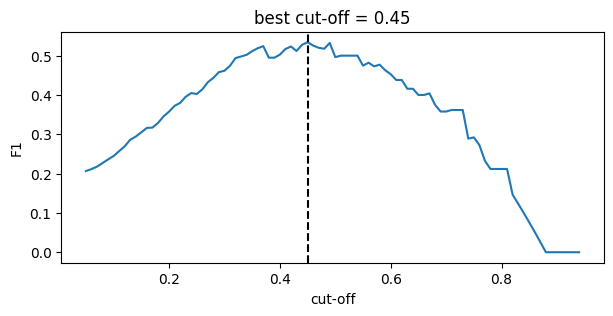

In [13]:
ts = np.round(np.arange(0.05, 0.95, 0.01), 2)
f1s = [f1_score(y, oof >= t) for t in ts]
thr = float(ts[int(np.argmax(f1s))])
pred = (oof >= thr).astype(int)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(ts, f1s); ax.axvline(thr, ls="--", c="k")
ax.set(xlabel="cut-off", ylabel="F1", title=f"best cut-off = {thr}")
plt.show()

### 6b · Accuracy

{
 "auc": 0.8828,
 "recall": 0.5658,
 "precision": 0.5059,
 "accuracy": 0.89,
 "base_rate": 0.1114
}


,forecast: won't default,forecast: will default
actually repaid,564,42
actually defaulted,33,43


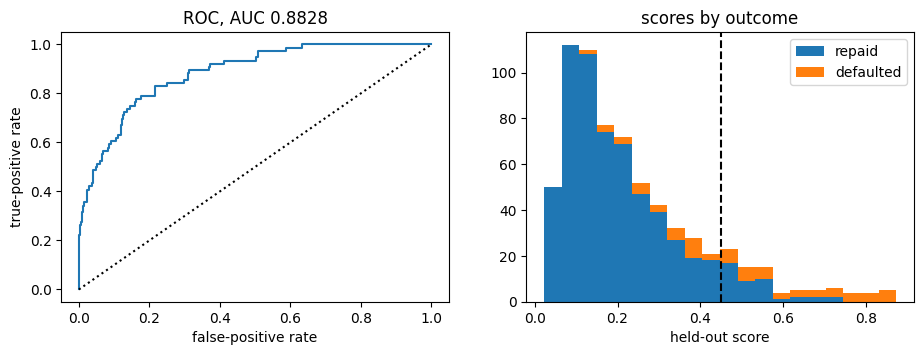

In [14]:
tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
metrics = {"auc": round(roc_auc_score(y, oof), 4), "recall": round(recall_score(y, pred), 4),
           "precision": round(precision_score(y, pred), 4), "accuracy": round(float((pred == y).mean()), 4),
           "base_rate": round(float(y.mean()), 4)}
print(json.dumps(metrics, indent=1))
display(pd.DataFrame([[tn, fp], [fn, tp]], index=["actually repaid", "actually defaulted"],
                     columns=["forecast: won't default", "forecast: will default"]))

fpr, tpr, _ = roc_curve(y, oof)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].plot(fpr, tpr); axs[0].plot([0, 1], [0, 1], "k:")
axs[0].set(xlabel="false-positive rate", ylabel="true-positive rate", title=f"ROC, AUC {metrics['auc']}")
axs[1].hist([oof[y == 0], oof[y == 1]], bins=20, label=["repaid", "defaulted"], stacked=True)
axs[1].axvline(thr, ls="--", c="k"); axs[1].legend(); axs[1].set(xlabel="held-out score", title="scores by outcome")
plt.show()

### 6c · Feature importance
How much the held-out AUC drops when each feature is shuffled, averaged over the folds. The dashboard shows the top 10.

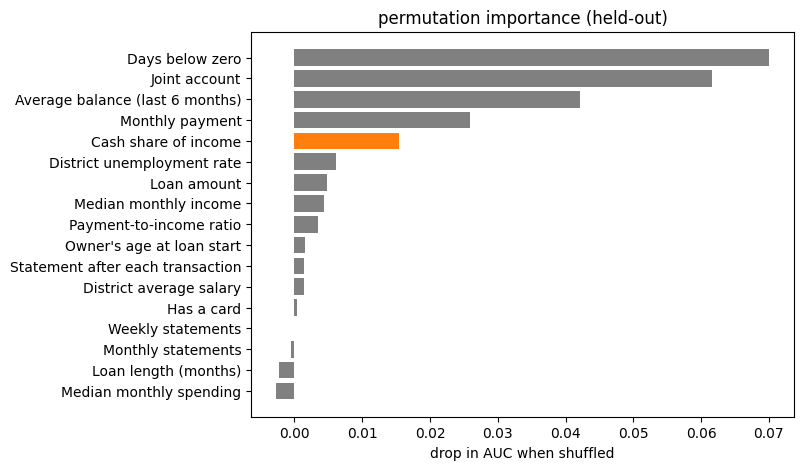

,auc_drop
neg_days,0.0700
joint,0.0616
balance,0.0421
payment,0.0259
cash_share,0.0154
district_unemp,0.0062
amount,0.0048
income,0.0044
pti,0.0034
age,0.0016


In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
s = imp.iloc[::-1]
ax.barh([FEATURES[k] for k in s.index], s.values, color=["C1" if k == "cash_share" else "grey" for k in s.index])
ax.set(xlabel="drop in AUC when shuffled", title="permutation importance (held-out)")
plt.show()
imp.round(4).to_frame("auc_drop")

## 7 · Why the cash-share grid is uneven

The what-if curves in section 8 rescore each borrower at a list (grid) of cash-share values. A forest is a step function: its prediction only changes where a tree **splits**.
So the grid must be fine wherever the splits are. Two facts drive this:
1. Real cash shares come in two groups: one near 0%, and a larger one packed between about 98.5% and 99.7%.
2. The forest's cash-share splits fall almost entirely inside those two groups.

An even 0–100% grid in 2.5% steps would jump from 97.5% straight to 100% and miss every split.

544 cash-share splits across 300 trees
where they fall: {Interval(0.0, 0.1, closed='right'): 90, Interval(0.1, 0.5, closed='right'): 28, Interval(0.5, 0.95, closed='right'): 13, Interval(0.95, 0.98, closed='right'): 0, Interval(0.98, 0.99, closed='right'): 67, Interval(0.99, 0.995, closed='right'): 194, Interval(0.995, 1.0, closed='right'): 152}


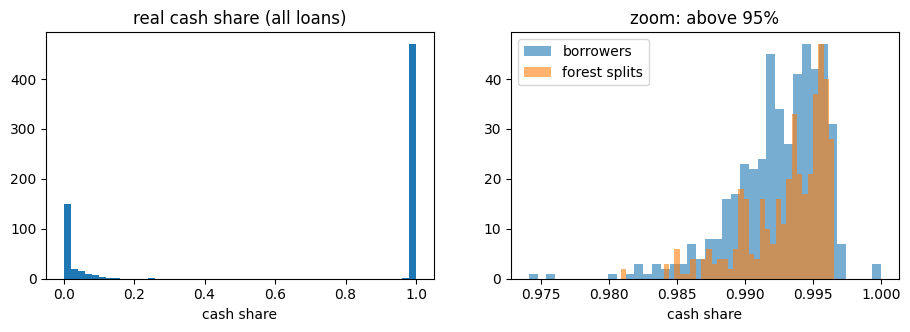

                size  default_rate
cash_share                        
(-0.001, 0.5]    210      0.061905
(0.95, 0.99]      90      0.088889
(0.99, 0.995]    267      0.119850
(0.995, 0.999]   112      0.178571
(0.999, 1.0]       3      1.000000


In [16]:
rf_all = make_forest().fit(X[cols], y)        # the same final model used in section 8
k_cash = cols.index("cash_share")
splits = np.concatenate([t.tree_.threshold[t.tree_.feature == k_cash] for t in rf_all.estimators_])
print(f"{len(splits)} cash-share splits across {N_TREES} trees")
print("where they fall:", pd.cut(pd.Series(splits), [0, .1, .5, .95, .98, .99, .995, 1]).value_counts(sort=False).to_dict())

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
axs[0].hist(X.cash_share, bins=50); axs[0].set(title="real cash share (all loans)", xlabel="cash share")
axs[1].hist(X.cash_share[X.cash_share > 0.95], bins=40, alpha=.6, label="borrowers")
axs[1].hist(splits[splits > 0.95], bins=40, alpha=.6, label="forest splits")
axs[1].set(title="zoom: above 95%", xlabel="cash share"); axs[1].legend()
plt.show()
print(X.groupby(pd.cut(X.cash_share, [0, .5, .95, .99, .995, .999, 1.0001], include_lowest=True), observed=True)
       .defaulted.agg(["size", "mean"]).rename(columns={"mean": "default_rate"}))

In [17]:
# 0-10% in 0.5% steps, 10-95% in 5% steps, 95-100% in 0.1% steps -> 88 points
GRID = np.unique(np.round(np.concatenate([np.arange(0, 0.1, 0.005), np.arange(0.1, 0.95, 0.05),
                                          np.arange(0.95, 1.0005, 0.001)]), 4))
print(len(GRID), "grid points:", GRID[:5], "...", GRID[-5:])

88 grid points: [0.    0.005 0.01  0.015 0.02 ] ... [0.996 0.997 0.998 0.999 1.   ]


## 8 · What-if curves

For **each borrower**, copy their row once per grid value, change only `cash_share`, and score every copy with the forest trained on all loans.
This gives one curve per borrower (an *ICE* curve). The **average** of all curves (a *partial dependence* curve) is the bold line on the dashboard.

These curves show what the model learned, not cause and effect. Borrowers with lots of cash income differ in other ways too.
They come from `rf_all`, which saw every loan, so at a borrower's real cash share the curve can differ from their held-out score.

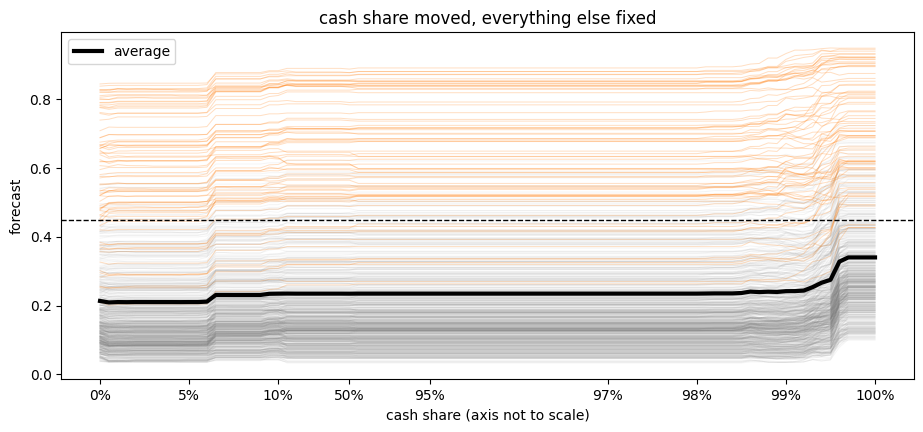

average forecast at 98%: 0.235  at 100%: 0.340
per-borrower swing: median 0.134, 90th pct 0.197
borrowers whose verdict can flip by moving cash share alone: 74 of 682


In [18]:
rep = X[cols].loc[X.index.repeat(len(GRID))].copy()
rep["cash_share"] = np.tile(GRID, len(X))
ice = rf_all.predict_proba(rep)[:, 1].reshape(len(X), len(GRID))
pdp = ice.mean(axis=0)

xs = np.arange(len(GRID))                     # plot on grid index = the dashboard's zoomed axis
ticks = [i for i, g in enumerate(GRID) if g in (0, .05, .1, .5, .95, .97, .98, .99, 1)]
fig, ax = plt.subplots(figsize=(11, 4.5))
for i in range(len(X)):
    ax.plot(xs, ice[i], c="C1" if y[i] else "grey", alpha=.25 if y[i] else .08, lw=.7)
ax.plot(xs, pdp, c="k", lw=3, label="average")
ax.axhline(thr, ls="--", c="k", lw=1)
ax.set_xticks(ticks, [f"{GRID[i]:.0%}" for i in ticks])
ax.set(xlabel="cash share (axis not to scale)", ylabel="forecast", title="cash share moved, everything else fixed")
ax.legend(); plt.show()

swing = ice.max(1) - ice.min(1)
flips = ((ice.min(1) < thr) & (ice.max(1) >= thr)).sum()
print(f"average forecast at 98%: {pdp[np.abs(GRID - .98).argmin()]:.3f}  at 100%: {pdp[-1]:.3f}")
print(f"per-borrower swing: median {np.median(swing):.3f}, 90th pct {np.quantile(swing, .9):.3f}")
print(f"borrowers whose verdict can flip by moving cash share alone: {flips} of {len(X)}")

## 9 · Check and export

The next cell assembles exactly what the dashboard reads.
- The cell after it compares the results with the current `data/model.js`. With unchanged settings everything should match.
- To publish your changes to the dashboard, set `WRITE_MODEL_JS = True` in section 1 and rerun.

In [19]:
order = X.sort_values(["defaulted", "account_id"], ascending=[False, True]).index
keep = np.unique(np.linspace(0, len(fpr) - 1, 60).astype(int))
out = {
    "meta": {"loans": int(len(X)), "defaulted": int(y.sum()), "n_estimators": N_TREES, "max_depth": MAX_DEPTH,
             "min_samples_leaf": MIN_LEAF, "folds": FOLDS, "seed": SEED, "features": len(cols),
             "months_pre_min": int(X.months_pre.min()), "months_pre_median": float(X.months_pre.median()),
             "cash_share_range": [round(float(X.cash_share.min()), 4), round(float(X.cash_share.max()), 4)]},
    "metrics": metrics,
    "threshold": thr,
    "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "roc": [[round(float(fpr[i]), 4), round(float(tpr[i]), 4)] for i in keep],
    "importance": [{"key": k, "label": FEATURES[k], "value": round(float(v), 4)} for k, v in imp.head(10).items()],
    "grid": GRID.tolist(),
    "pdp": np.round(pdp, 4).tolist(),
    "borrowerFields": ["account_id", "defaulted", "cash_share", "oof_prob", "income", "amount", "payment", "joint", "card", "curve"],
    "borrowers": [[int(X.account_id[i]), int(y[i]), round(float(X.cash_share[i]), 4), round(float(oof[i]), 3),
                   round(float(X.income[i]), 0), round(float(X.amount[i]), 0), round(float(X.payment[i]), 0),
                   int(X.joint[i]), int(X.card[i]), np.round(ice[i], 3).tolist()] for i in order],
}
print({k: out[k] for k in ["metrics", "threshold", "confusion"]})

{'metrics': {'auc': 0.8828, 'recall': 0.5658, 'precision': 0.5059, 'accuracy': 0.89, 'base_rate': 0.1114}, 'threshold': 0.45, 'confusion': {'tn': 564, 'fp': 42, 'fn': 33, 'tp': 43}}

In [20]:
dest = ROOT / "data" / "model.js"
if dest.exists():
    cur = json.loads(dest.read_text(encoding="utf-8").split("window.MODEL = ", 1)[1].rstrip().rstrip(";"))
    for k in ["meta", "metrics", "threshold", "confusion", "importance", "grid", "pdp"]:
        print(f"{k:12s}", "same" if cur[k] == out[k] else "DIFFERENT")
    same_b = cur["borrowers"] == out["borrowers"]
    print(f"{'borrowers':12s}", "same" if same_b else "DIFFERENT")

if WRITE_MODEL_JS:
    dest.write_text("// generated by prep/build_model.py - do not edit by hand\nwindow.MODEL = "
                    + json.dumps(out, separators=(",", ":")) + ";\n", encoding="utf-8")
    print("wrote", dest, f"({dest.stat().st_size / 1024:.0f} KB)")
else:
    print("\nWRITE_MODEL_JS is False: data/model.js left untouched")

meta         same
metrics      same
threshold    same
confusion    same
importance   same
grid         same
pdp          same
borrowers    same

WRITE_MODEL_JS is False: data/model.js left untouched
